# PortfolioPilot - 02 Exploration (training data only)

**Run the cells in order, top to bottom.** Install the package first (`pip install -e .` from the project root).

Rule for M3: the test sets are created in notebook 01 and then never explored. Every statistic, cap,
table and figure uses **training data only**.

## Step 1 - Setting up

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from portfolio_pilot.config import Results, ensure_output_dirs, load_config

cfg = load_config()
ensure_output_dirs(cfg)
P, SEED = cfg["paths"], cfg["seed"]
results = Results(P["numbers_file"])    # every count quoted in the report; saved in the last cell
np.random.seed(SEED)

plt.rcParams.update({"figure.dpi": 110, "font.size": 9,
                     "axes.spines.top": False, "axes.spines.right": False})

def save_fig(fig, name):
    fig.tight_layout()
    fig.savefig(P["figures_dir"] / f"{name}.png", dpi=150, bbox_inches="tight")
    plt.show()

## Step 2 - Build features (caps fitted on training data only)

In [2]:
from portfolio_pilot.features import build_partition_features
from portfolio_pilot.prepare import fit_caps
from portfolio_pilot.split import load_partitions

hh = pd.read_csv(P["processed_dir"] / "scf_clean.csv")
parts = load_partitions(hh, P["processed_dir"] / "scf_split_ids.csv")
caps = fit_caps(parts["train"], cfg["scf"]["cap_quantile"], results)     # caps come from training households only
feats = build_partition_features(parts, caps)
tr = feats["train"]
results["features"]

{'caps_from_train': {'dti': 7.322105263125945,
  'liq_to_income': 4.421218403259946},
 'train_ratio_undefined_income_le_0': 18,
 'train_dti_above_cap': 31,
 'train_lti_above_cap': 31,
 'train_fin_zero': 34}

## Step 3 - Outlier check: 3xIQR fences on raw and inverse hyperbolic sine (asinh) transformed features (training data only)

In [3]:
from portfolio_pilot.clean import iqr_outlier_table

outliers = iqr_outlier_table(tr, ["income", "asinh_income", "networth", "asinh_networth", "liq", "asinh_liq"])
outliers.to_csv(P["tables_dir"] / "scf_outliers_train.csv", index=False)
results.note("outliers", "table", outliers.to_dict(orient="records"))
outliers

,variable,n_beyond_3iqr,min,max
0,income,396,0.000000,2.193114e+08
1,asinh_income,30,0.000000,1.989915e+01
2,networth,443,-207050.000000,3.077095e+09
3,asinh_networth,229,-12.933863,2.254040e+01
4,liq,364,0.000000,1.478910e+08
5,asinh_liq,0,0.000000,1.950513e+01


## Step 4 - SCF figures

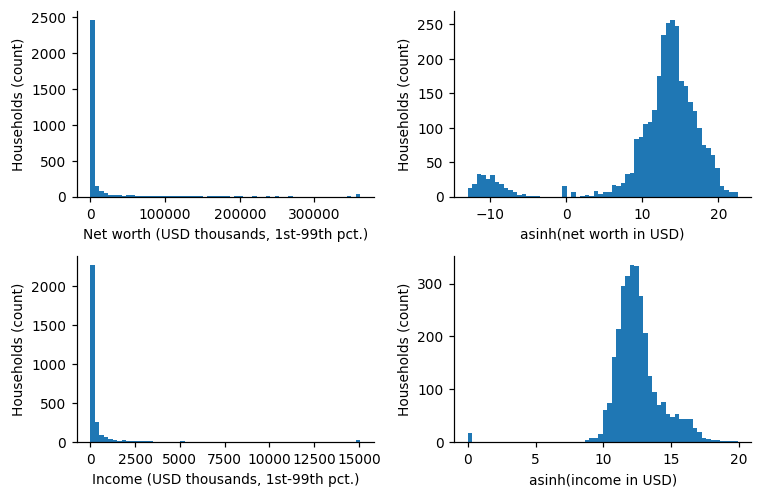

In [4]:
# Figure 2: skew before and after asinh
fig, axes = plt.subplots(2, 2, figsize=(7, 4.6))
for row, (c, lab) in enumerate([("networth", "Net worth"), ("income", "Income")]):
    lo, hi = tr[c].quantile([0.01, 0.99])
    axes[row, 0].hist(tr[c].clip(lo, hi) / 1e3, bins=60)
    axes[row, 0].set_xlabel(f"{lab} (USD thousands, 1st-99th pct.)")
    axes[row, 1].hist(np.arcsinh(tr[c]), bins=60)
    axes[row, 1].set_xlabel(f"asinh({lab.lower()} in USD)")
    for a in axes[row]:
        a.set_ylabel("Households (count)")
save_fig(fig, "fig02_skew_asinh")

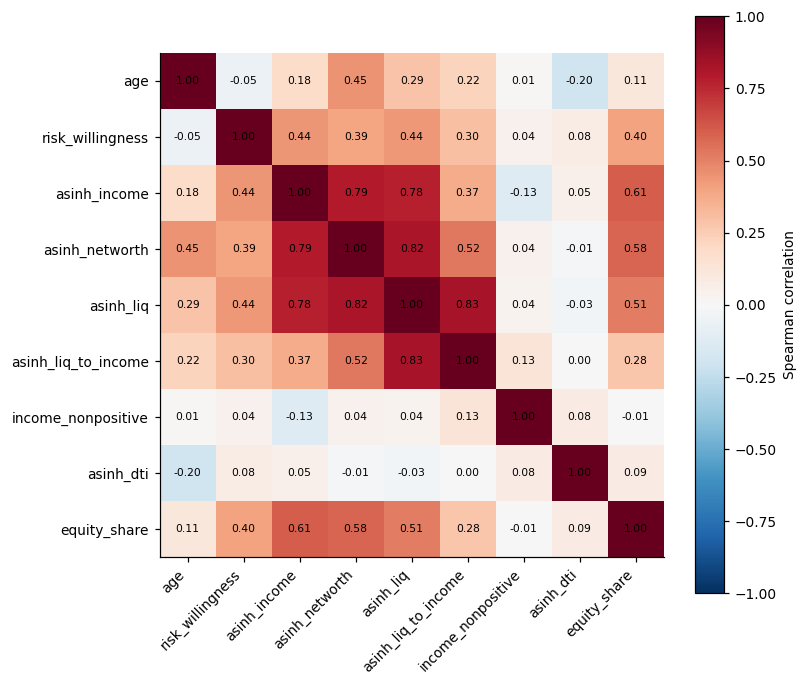

In [5]:
# Figure 4: correlations among features
from portfolio_pilot.features import CLASSIFIER_FEATURES, CLUSTER_FEATURES

def corr_plot(df, cols, name, method):
    c = df[cols].corr(method=method)
    fig, ax = plt.subplots(figsize=(0.6 * len(cols) + 2, 0.55 * len(cols) + 1.5))
    im = ax.imshow(c, vmin=-1, vmax=1, cmap="RdBu_r")
    ax.set_xticks(range(len(cols)), cols, rotation=45, ha="right")
    ax.set_yticks(range(len(cols)), cols)
    for i in range(len(cols)):
        for j in range(len(cols)):
            ax.text(j, i, f"{c.iloc[i, j]:.2f}", ha="center", va="center", fontsize=7)
    fig.colorbar(im, ax=ax, label=f"{method.capitalize()} correlation")
    save_fig(fig, name)
    return c

all_feats = list(dict.fromkeys(CLASSIFIER_FEATURES + CLUSTER_FEATURES))
scf_corr = corr_plot(tr, all_feats, "fig04_scf_corr", "spearman")
results.note("eda", "spearman", scf_corr.round(3).to_dict())

## Step 5 - ETF exploration (training period only)

Extreme-return dates: ['2016-06-24', '2016-11-09', '2020-03-06', '2020-03-09', '2020-03-10', '2020-03-11', '2020-03-12', '2020-03-13', '2020-03-16', '2020-03-17', '2020-03-18', '2020-03-19', '2020-03-20', '2020-03-23', '2020-03-24', '2020-03-30', '2020-04-06', '2020-06-11', '2020-08-11', '2020-11-09', '2021-11-26']


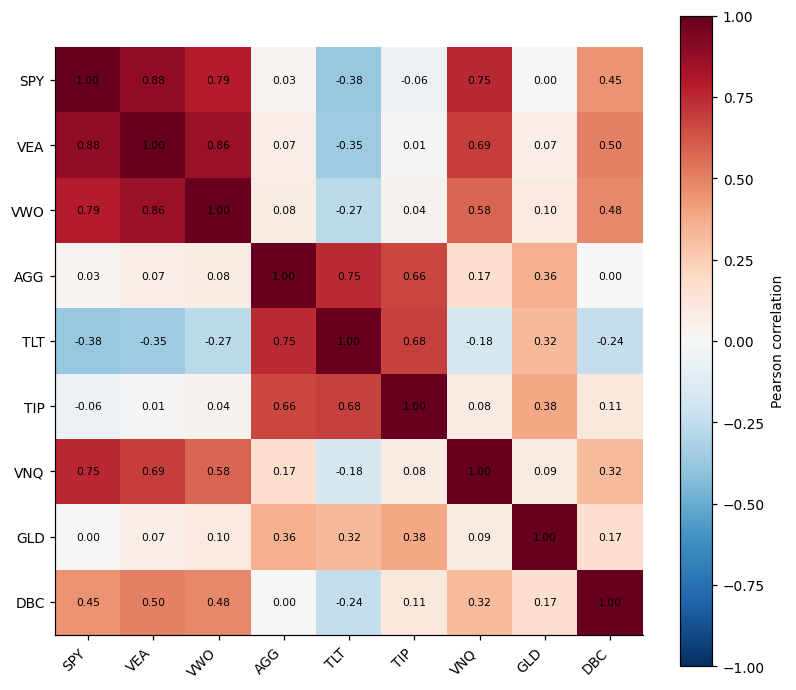

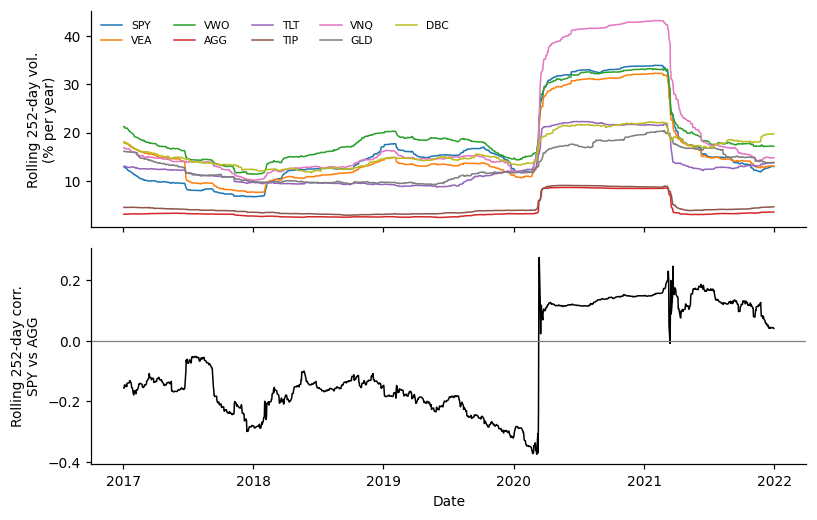

In [6]:
TICKERS = cfg["etf"]["tickers"]
etr = pd.read_csv(P["processed_dir"] / "etf_returns_train.csv", index_col=0, parse_dates=True)

z = (etr - etr.mean()) / etr.std()
flags = z.abs() > 5
results.note("etf_outliers", "n_flagged_by_ticker", flags.sum().to_dict())
results.note("etf_outliers", "dates", [str(d.date()) for d in etr.index[flags.any(axis=1)]])
results.note("etf_eda", "annual_vol_train", (etr.std() * np.sqrt(252)).to_dict())
print("Extreme-return dates:", results["etf_outliers"]["dates"])

etf_corr = corr_plot(etr, TICKERS, "fig06_etf_corr", "pearson")
results.note("etf_eda", "corr_train", etf_corr.round(3).to_dict())

fig, axes = plt.subplots(2, 1, figsize=(7.5, 4.8), sharex=True)
vol = etr.rolling(252).std() * np.sqrt(252) * 100
for c in TICKERS:
    axes[0].plot(vol.index, vol[c], lw=1, label=c)
axes[0].set_ylabel("Rolling 252-day vol.\n(% per year)")
axes[0].legend(ncol=5, frameon=False, fontsize=7)
axes[1].plot(etr.index, etr["SPY"].rolling(252).corr(etr["AGG"]), color="k", lw=1)
axes[1].axhline(0, color="grey", lw=0.8)
axes[1].set_ylabel("Rolling 252-day corr.\nSPY vs AGG")
axes[1].set_xlabel("Date")
save_fig(fig, "fig07_etf_rolling")

## Step 6 - Inspect extreme ETF returns (training period)
Every daily return beyond 5 training standard deviations, with its date, ETF and size, to check whether each is a real market event or a data error.

In [7]:
flagged = (etr[z.abs() > 5].stack().rename("log_return").to_frame()
           .assign(z=z.stack(), pct_return=lambda d: (np.exp(d["log_return"]) - 1) * 100)
           .round(2))
flagged.index.names = ["date", "ticker"]
flagged.sort_index()

log_return     z  pct_return
date       ticker                              
2016-01-05 AGG            NaN  0.12         NaN
           DBC            NaN -0.95         NaN
           GLD            NaN  0.28         NaN
           SPY            NaN  0.09         NaN
           TIP            NaN -0.26         NaN
...                       ...   ...         ...
2021-12-31 TIP            NaN -0.45         NaN
           TLT            NaN  0.20         NaN
           VEA            NaN -0.07         NaN
           VNQ            NaN  0.17         NaN
           VWO            NaN -0.23         NaN

[13590 rows x 3 columns]

## Save the numbers quoted in the report

In [8]:
results.save()
print("Saved", P["numbers_file"])

Saved C:\Users\jp\Documents\DAE\7275\Pilot\Portfolio-Pilot\reports\numbers.json
